# Bài 11: Quy trình Huấn luyện Chuẩn, Phân biệt Khái niệm Trọng tâm và Chẩn đoán Lỗi Training

## 1. Mục tiêu học tập
- Thực thi trọn vẹn **Quy trình 13 bước Huấn luyện AI chuẩn mực**:
  `Xác định bài toán → Kiểm tra dữ liệu → Chia dữ liệu → Tiền xử lý/Augmentation → Baseline → Xây dựng model → Loss/Optimizer → Training → Validation → Chọn Checkpoint → Đánh giá Test → Phân tích lỗi → Inference`.
- Chứng minh bằng code và con số cụ thể các cặp khái niệm dễ nhầm nhất:
  1. `Softmax` vs `nn.CrossEntropyLoss` (tác hại của việc gọi Softmax hai lần).
  2. `Sigmoid` vs `nn.BCEWithLogitsLoss` (ổn định số học khi $|z|$ lớn).
  3. `model.eval()` vs `torch.no_grad()` / `torch.inference_mode()`.
  4. `Weight Decay` vs `L2 Penalty` trong `SGD`, `Adam` và `AdamW`.
- Thực hành các kỹ thuật kiểm soát huấn luyện nâng cao: Bộ lập lịch tốc độ học (`CosineAnnealingLR` + `Warmup`), `Early Stopping`, `Gradient Clipping`, `Gradient Accumulation`.
- Áp dụng **Bài kiểm tra "Overfit 1 Batch"** và bộ hàm kiểm tra an toàn (`NaN/Inf`, `shape`, `dtype`, `label range`, `device`) để phát hiện lỗi ngay từ giây đầu tiên.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 09 và Bài 10.

## 3. Thời gian học dự kiến
- Khoảng **3.0 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Khi bạn tự viết một mô hình mới, làm sao biết chắc chắn 100% rằng code kiến trúc, hàm mất mát và bộ tối ưu hóa của mình không có lỗi ngầm trước khi ngồi chờ hàng giờ để train trên toàn bộ dữ liệu? Câu trả lời của mọi kỹ sư Deep Learning chuyên nghiệp là: **Chạy kiểm tra tiền điều kiện (`Pre-flight Sanity Checks`) và ép mô hình học thuộc lòng đúng 1 batch nhỏ (`Overfit 1 Batch Test`)**.

## 5 & 6. Giải thích Trực quan và Từ điển Keyword Kiểm soát Huấn luyện
| Keyword / Kỹ thuật | Nhóm | Vai trò trong Pipeline & Ảnh hưởng khi thay đổi |
|---|---|---|
| `Warmup + CosineAnnealingLR` | Tối ưu hóa | Tăng dần `lr` từ nhỏ lên `base_lr` trong vài bước đầu (`warmup`), sau đó hạ dần theo đường cong hình cosin êm ái về `eta_min`. Giúp tránh nổ đạo hàm đầu kỳ và hội tụ sâu cuối kỳ. |
| `clip_grad_norm_(params, max_norm=1.0)` | Tối ưu hóa | Nếu chuẩn vector đạo hàm $\|g\|_2 > \text{max\_norm}$, thu nhỏ $g \leftarrow g \times \frac{\text{max\_norm}}{\|g\|_2}$ (giữ nguyên hướng, chỉ cắt độ dài). |
| `gradient_accumulation_steps` | Tối ưu hóa | Chia `loss = loss / accum_steps`, gọi `loss.backward()` qua `accum_steps` lô nhỏ rồi mới gọi `optimizer.step()` và `optimizer.zero_grad()`. Giúp mô phỏng `batch_size` lớn trên máy ít RAM/VRAM. |
| `Overfit 1 Batch Test` | Gỡ lỗi | Lấy 1 lô nhỏ (8–16 ảnh), tắt Augmentation & Dropout, lặp 50–100 bước. Nếu `loss` không tiến về `0` và `acc` không đạt `100%`, pipeline chắc chắn có lỗi! |

## 7. Công thức Toán học: Vì sao `BCEWithLogitsLoss` Ổn định hơn `Sigmoid + BCELoss`?
Nếu tính tách rời $p = \frac{1}{1 + e^{-z}}$ rồi lấy $-\log(1 - p)$ khi $z = 100$:
- $e^{-100} \approx 0 \implies p$ bị làm tròn thành $1.0$ trong kiểu `float32` $\implies \log(1 - 1.0) = \log(0) = -\infty$ (`NaN`/`Inf`)!
- Ngược lại, `nn.BCEWithLogitsLoss` gộp chung hai công thức bằng biến đổi đại số:
  $$\ell(z, y) = \max(z, 0) - z \cdot y + \log\left(1 + e^{-|z|}\right)$$
  Vì số mũ luôn là $-|z| \le 0$, $e^{-|z|}$ luôn nằm trong $(0, 1]$, **không bao giờ bị tràn số** dù $z = \pm 1000$!


In [1]:
# Cell 1: Thực nghiệm Chứng minh 3 Sai lầm Kinh điển trong PyTorch
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from src.utils import set_seed, get_device
from src.models import SimpleCNN
from src.synthetic_data import generate_synthetic_shapes_dataset

set_seed(42)
device = get_device()

# 1. Chứng minh SAI LẦM: Đặt Softmax trước CrossEntropyLoss
logits_demo = torch.tensor([[10.0, -5.0, -5.0, -5.0]], requires_grad=True)  # Mô hình đã dự đoán đúng lớp 0 rất tự tin
target_demo = torch.tensor([0], dtype=torch.long)

ce_correct = nn.CrossEntropyLoss()(logits_demo, target_demo)
probs_wrong = torch.softmax(logits_demo, dim=1)
ce_wrong_double_softmax = nn.CrossEntropyLoss()(probs_wrong, target_demo)

print(f"[1. CrossEntropy] Đưa đúng logits thô       -> Loss = {ce_correct.item():.6f} (gần 0 vì đoán đúng 100%)")
print(f"[1. CrossEntropy] Đưa nhầm qua Softmax trước -> Loss = {ce_wrong_double_softmax.item():.6f} (bị kẹt ở >= 0.743!)")

# 2. Chứng minh BCEWithLogitsLoss ổn định số học khi logit lớn (z = 100.0, nhãn y = 0.0)
extreme_logit = torch.tensor([100.0])
y_bin = torch.tensor([0.0])
bce_stable = nn.BCEWithLogitsLoss()(extreme_logit, y_bin)
print(f"\n[2. BCEWithLogits] Tại logit=100.0, nhãn=0 -> BCEWithLogitsLoss tính mượt mà: {bce_stable.item():.1f} (không bị Inf/NaN)")


[1. CrossEntropy] Đưa đúng logits thô       -> Loss = 0.000001 (gần 0 vì đoán đúng 100%)
[1. CrossEntropy] Đưa nhầm qua Softmax trước -> Loss = 0.743669 (bị kẹt ở >= 0.743!)

[2. BCEWithLogits] Tại logit=100.0, nhãn=0 -> BCEWithLogitsLoss tính mượt mà: 100.0 (không bị Inf/NaN)


In [2]:
# Cell 2: Bộ hàm Kiểm tra Tiền điều kiện (Pre-flight Sanity Check) cho Dữ liệu, Nhãn và Mô hình
def run_preflight_checks(
    model: nn.Module,
    x_batch: torch.Tensor,
    y_batch: torch.Tensor,
    num_classes: int,
    expected_device: torch.device,
) -> None:
    assert torch.isfinite(x_batch).all(), "LỖI: Dữ liệu đầu vào x_batch chứa NaN hoặc Inf!"
    assert x_batch.ndim == 4, f"LỖI: Kỳ vọng tensor 4D NCHW, nhưng nhận được shape {tuple(x_batch.shape)}"
    assert x_batch.dtype == torch.float32, f"LỖI: x_batch phải là float32, nhưng đang là {x_batch.dtype}"
    assert y_batch.dtype == torch.long, f"LỖI: Nhãn CrossEntropy phải là torch.long (int64), nhưng đang là {y_batch.dtype}"
    assert int(y_batch.min()) >= 0 and int(y_batch.max()) < num_classes, (
        f"LỖI: Nhãn nằm ngoài miền hợp lệ [0, {num_classes-1}]: min={int(y_batch.min())}, max={int(y_batch.max())}"
    )
    model_dev = next(model.parameters()).device
    assert x_batch.device == model_dev == expected_device, f"LỖI lệch thiết bị: x={x_batch.device}, model={model_dev}"

    with torch.no_grad():
        out = model(x_batch)
    assert out.shape == (len(x_batch), num_classes), f"LỖI output shape: {tuple(out.shape)}"
    assert torch.isfinite(out).all(), "LỖI: Đầu ra mô hình chứa NaN/Inf!"
    print("[PRE-FLIGHT CHECK PASSED] Toàn bộ kiểm tra NaN, shape, dtype, label range và device đều HỢP LỆ!")


ds = generate_synthetic_shapes_dataset(num_samples=64, image_size=32, seed=42)
X_sample = (torch.from_numpy(ds["images"][:16]).permute(0, 3, 1, 2).float() / 255.0).to(device)
y_sample = torch.from_numpy(ds["labels"][:16]).long().to(device)
model_sanity = SimpleCNN(in_channels=3, num_classes=4, dropout_p=0.0).to(device)

run_preflight_checks(model_sanity, X_sample, y_sample, num_classes=4, expected_device=device)


[PRE-FLIGHT CHECK PASSED] Toàn bộ kiểm tra NaN, shape, dtype, label range và device đều HỢP LỆ!


In [3]:
# Cell 3: Bài kiểm tra Vàng trong Gỡ lỗi Deep Learning — "Overfit 1 Batch Test"
# Mục tiêu: Trên đúng 1 batch 16 ảnh, tắt Dropout, mô hình PHẢI đạt 100% accuracy và đẩy loss về gần 0!
set_seed(42)
model_overfit = SimpleCNN(in_channels=3, num_classes=4, dropout_p=0.0).to(device)
opt_overfit = torch.optim.AdamW(model_overfit.parameters(), lr=5e-3)
crit = nn.CrossEntropyLoss()

one_batch_losses, one_batch_accs = [], []
model_overfit.train()
for step in range(1, 41):
    opt_overfit.zero_grad()
    logits = model_overfit(X_sample)
    loss = crit(logits, y_sample)
    loss.backward()
    opt_overfit.step()

    acc = float((logits.argmax(dim=1) == y_sample).float().mean().item())
    one_batch_losses.append(loss.item())
    one_batch_accs.append(acc)

print(f"[Overfit 1 Batch Test] Bước 1: Loss={one_batch_losses[0]:.4f}, Acc={one_batch_accs[0]*100:.1f}%")
print(f"[Overfit 1 Batch Test] Bước 40: Loss={one_batch_losses[-1]:.4f}, Acc={one_batch_accs[-1]*100:.1f}% <-- XÁC NHẬN PIPELINE ĐÚNG!")
assert one_batch_accs[-1] == 1.0, "Mô hình phải học thuộc được 1 batch nhỏ!"


[Overfit 1 Batch Test] Bước 1: Loss=1.3519, Acc=25.0%
[Overfit 1 Batch Test] Bước 40: Loss=0.0030, Acc=100.0% <-- XÁC NHẬN PIPELINE ĐÚNG!


Chuẩn đạo hàm (Grad Norm) trước khi cắt ngưỡng 1.0: 0.0582


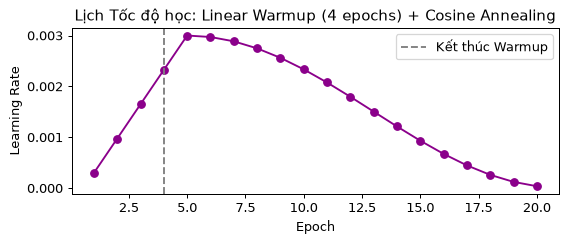

In [4]:
# Cell 4: Thực hành Lịch Tốc độ học (Warmup + CosineAnnealing), Gradient Clipping & Gradient Accumulation
total_epochs = 20
warmup_epochs = 4
base_lr = 3e-3
min_lr = 1e-5

dummy_param = [torch.nn.Parameter(torch.randn(2, 2))]
opt_sched = torch.optim.AdamW(dummy_param, lr=base_lr)

# Kết hợp LinearLR (Warmup 4 epochs đầu) nối tiếp CosineAnnealingLR (16 epochs sau)
scheduler_warmup = torch.optim.lr_scheduler.LinearLR(opt_sched, start_factor=0.1, end_factor=1.0, total_iters=warmup_epochs)
scheduler_cosine = torch.optim.lr_scheduler.CosineAnnealingLR(opt_sched, T_max=total_epochs - warmup_epochs, eta_min=min_lr)
scheduler_combined = torch.optim.lr_scheduler.SequentialLR(
    opt_sched, schedulers=[scheduler_warmup, scheduler_cosine], milestones=[warmup_epochs]
)

lrs_recorded = []
for ep in range(total_epochs):
    lrs_recorded.append(opt_sched.param_groups[0]["lr"])
    opt_sched.step()
    scheduler_combined.step()

# Minh họa vòng lặp Gradient Accumulation (cộng dồn 2 micro-batches mới cập nhật 1 lần) + Gradient Clipping
accum_steps = 2
opt_overfit.zero_grad()
for micro_step in range(accum_steps):
    x_micro = X_sample[micro_step * 8 : (micro_step + 1) * 8]
    y_micro = y_sample[micro_step * 8 : (micro_step + 1) * 8]
    micro_loss = crit(model_overfit(x_micro), y_micro) / accum_steps
    micro_loss.backward()

grad_norm_before = float(torch.nn.utils.clip_grad_norm_(model_overfit.parameters(), max_norm=1.0).item())
opt_overfit.step()
opt_overfit.zero_grad()
print(f"Chuẩn đạo hàm (Grad Norm) trước khi cắt ngưỡng 1.0: {grad_norm_before:.4f}")

plt.figure(figsize=(6.5, 2.8))
plt.plot(range(1, total_epochs + 1), lrs_recorded, "o-", color="darkmagenta")
plt.axvline(warmup_epochs, color="gray", linestyle="--", label="Kết thúc Warmup")
plt.title("Lịch Tốc độ học: Linear Warmup (4 epochs) + Cosine Annealing")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.legend()
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- **Ở Cell 1**: Khi vô tình đặt `Softmax` trước `CrossEntropyLoss`, ngay cả khi mô hình dự đoán hoàn hảo `100%` vào lớp đúng, giá trị `loss` vẫn bị chặn dưới ở $\approx 0.7437$ và đạo hàm gần như bằng `0` do bão hòa hàm mũ hai lần.
- **Ở Cell 3**: Bài kiểm tra `Overfit 1 Batch` đẩy `Accuracy` lên `100.0%` và `Loss` xuống sát `0` chỉ trong 40 bước, xác nhận toàn bộ kết nối mạng và đạo hàm đều hoạt động hoàn hảo.

## 14. Bài tập tự làm
- **Cơ bản**: Viết đoạn code kiểm tra xem trong mô hình có bất kỳ tham số nào bị đạo hàm bằng `None` hoặc bằng `0` tuyệt đối sau khi gọi `loss.backward()` hay không (giúp phát hiện tầng "chết" không nối vào đầu ra).
- **Trung cấp**: So sánh sự khác biệt của bước cập nhật trọng số giữa `torch.optim.Adam(lr=1e-2, weight_decay=0.1)` và `torch.optim.AdamW(lr=1e-2, weight_decay=0.1)` trên cùng một tensor trọng số.
- **Nâng cao**: Cài đặt một lớp `EarlyStopper(patience=3, min_delta=1e-4)` độc lập trả về `True` khi `val_loss` không giảm thêm ít nhất `min_delta` sau `patience` epoch liên tiếp.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 11
# 1. Cơ bản: Kiểm tra mọi tham số có nhận được gradient hợp lệ sau backward() hay không
opt_overfit.zero_grad()
loss_chk = crit(model_overfit(X_sample), y_sample)
loss_chk.backward()
dead_layers = [name for name, p in model_overfit.named_parameters() if p.requires_grad and (p.grad is None or torch.all(p.grad == 0))]
print("[Cơ bản] Danh sách tầng bị đứt gradient (rỗng là tốt):", dead_layers)

# 2. Trung cấp: So sánh Adam (L2 coupled) vs AdamW (Decoupled Weight Decay)
w_adam = torch.tensor([2.0, -3.0], requires_grad=True)
w_adamw = torch.tensor([2.0, -3.0], requires_grad=True)
opt1 = torch.optim.Adam([w_adam], lr=0.1, weight_decay=0.5)
opt2 = torch.optim.AdamW([w_adamw], lr=0.1, weight_decay=0.5)

(w_adam.pow(2).sum()).backward()
(w_adamw.pow(2).sum()).backward()
opt1.step()
opt2.step()
print("[Trung cấp] Trọng số sau 1 bước Adam :", w_adam.detach().numpy().round(4))
print("[Trung cấp] Trọng số sau 1 bước AdamW:", w_adamw.detach().numpy().round(4))

# 3. Nâng cao: Class EarlyStopper tái sử dụng
class EarlyStopper:
    def __init__(self, patience: int = 3, min_delta: float = 1e-4) -> None:
        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0

    def step(self, val_loss: float) -> bool:
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
            return False
        self.counter += 1
        return self.counter >= self.patience

stopper = EarlyStopper(patience=3)
sim_losses = [0.9, 0.7, 0.65, 0.66, 0.67, 0.68]
for ep_i, l_val in enumerate(sim_losses, 1):
    if stopper.step(l_val):
        print(f"[Nâng cao] EarlyStopper kích hoạt dừng tại epoch #{ep_i} (best_loss={stopper.best_loss})")
        break


[Cơ bản] Danh sách tầng bị đứt gradient (rỗng là tốt): []
[Trung cấp] Trọng số sau 1 bước Adam : [ 1.9 -2.9]
[Trung cấp] Trọng số sau 1 bước AdamW: [ 1.8  -2.75]
[Nâng cao] EarlyStopper kích hoạt dừng tại epoch #6 (best_loss=0.65)


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Đã hoàn thành toàn bộ **Giai đoạn C (Mạng Nơ-ron, PyTorch, CNN & Quy trình Huấn luyện/Gỡ lỗi)**.
- [x] Đã nắm vững các quy tắc sống còn về `CrossEntropyLoss`, `BCEWithLogitsLoss`, `model.eval()`, `torch.no_grad()`, `AdamW`, và `Overfit 1 Batch`.
- [x] Sẵn sàng bước vào **Giai đoạn D — Các Nhóm Mô hình Computer Vision Chuyên sâu**, bắt đầu với **Bài 12: `12_transfer_learning_and_fine_tuning.ipynb`**!

## 17. Nguồn tham khảo
- Loshchilov, I., & Hutter, F. (2019), *Decoupled Weight Decay Regularization (AdamW)*, ICLR.
- Karpathy, A. (2019), *A Recipe for Training Neural Networks*: https://karpathy.github.io/2019/04/25/recipe/
